<a href="https://colab.research.google.com/github/samvita0924/unit-1/blob/main/SMS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving spam_sms.csv to spam_sms.csv


In [ ]:
import pandas as pd

df = pd.read_csv("spam_sms.csv", encoding="latin-1")

df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
print(df.columns)
print(df.shape)

Index(['v1', 'v2'], dtype='object')
(5572, 2)


In [ ]:
df = df[['v1', 'v2']]

df.columns = ['label', 'message']

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
print(df.isnull().sum())

label      0
message    0
dtype: int64


In [ ]:
df = df.dropna()

In [ ]:
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

print(df['label'].value_counts())

label
0    4825
1     747
Name: count, dtype: int64


In [ ]:
print(df['label'].value_counts())

label
0    4825
1     747
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

df, _ = train_test_split(
    df,
    train_size=2000,
    stratify=df['label'],
    random_state=42
)

print(df.shape)
print(df['label'].value_counts())

(2000, 2)
label
0    1732
1     268
Name: count, dtype: int64


In [ ]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['message'] = df['message'].apply(clean_text)

df.head()

,label,message
180,0,you lifted my hopes with the offer of money i ...
3190,1,ur awarded a city break and could win a summer...
59,0,yesgauti and sehwag out of odi series
1722,0,thought praps you meant another one goodo ill ...
189,0,i jus reached home i go bathe first but my sis...


In [ ]:
X = df['message'].values
y = df['label'].values

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 1600
Testing samples: 400


In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(num_words=5000, oov_token="<OOV>")

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print(X_train_seq[:3])

[[313, 5, 1739], [49, 9, 5, 1740, 16, 5, 1741, 1169], [110, 172, 1742, 72, 9, 24, 6, 417, 1743, 51]]


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_len = 50

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_len,
    padding='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_len,
    padding='post'
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

Training shape: (1600, 50)
Testing shape: (400, 50)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(input_dim=5000, output_dim=64, input_length=50),
    LSTM(64),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - accuracy: 0.8664 - loss: 0.4529 - val_accuracy: 0.8531 - val_loss: 0.4206
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.8695 - loss: 0.3959 - val_accuracy: 0.8531 - val_loss: 0.4197
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.8695 - loss: 0.4058 - val_accuracy: 0.8531 - val_loss: 0.4190
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8695 - loss: 0.3953 - val_accuracy: 0.8531 - val_loss: 0.4044
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9469 - loss: 0.2006 - val_accuracy: 0.9312 - val_loss: 0.2683
Epoch 6/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9664 - loss: 0.1476 - val_accuracy: 0.9250 - val_loss: 0.2963
Epoch 7/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9703 - loss: 0.1461 - val_accuracy: 0.9219 - val_loss: 0.2988
Epoch 8/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9719 - loss: 0.1372 - val_accuracy: 0.9219 - v

In [ ]:
loss, accuracy = model.evaluate(X_test_pad, y_test)

print("Test Accuracy:", accuracy)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9425 - loss: 0.2394
Test Accuracy: 0.9424999952316284


In [ ]:
import numpy as np

y_prob = model.predict(X_test_pad)

y_pred = (y_prob > 0.5).astype(int).flatten()

print(y_pred[:20])

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

Accuracy : 0.9425
Precision: 0.9696969696969697
Recall   : 0.5925925925925926
F1-Score : 0.735632183908046


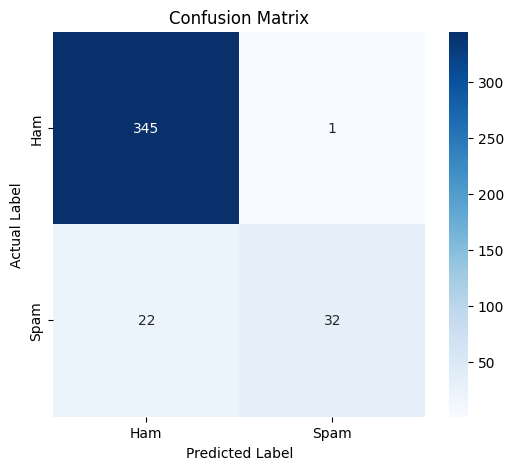

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Ham', 'Spam'],
    yticklabels=['Ham', 'Spam']
)

plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title('Confusion Matrix')

plt.show()

In [ ]:
def predict_sms(message):
    cleaned = clean_text(message)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=50,
        padding='post'
    )

    prediction = model.predict(padded, verbose=0)[0][0]

    if prediction > 0.5:
        print("SMS:", message)
        print("Prediction: SPAM")
        print("Probability:", round(float(prediction), 4))
    else:
        print("SMS:", message)
        print("Prediction: HAM")
        print("Probability:", round(float(1 - prediction), 4))

In [ ]:
predict_sms("Congratulations! You have won a free prize. Claim now!")

SMS: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
Probability: 0.9869


In [ ]:
predict_sms("Hey, are you coming to college tomorrow?")

SMS: Hey, are you coming to college tomorrow?
Prediction: HAM
Probability: 0.977


In [ ]:
predict_sms("You have won a cash reward. Click here to claim your prize!")

SMS: You have won a cash reward. Click here to claim your prize!
Prediction: SPAM
Probability: 0.9869
